# Predicting final grades using Multiple Linear Regression

In [1]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
cols = ['studytime', 'absences', 'G1', 'G2', 'G3'] 
df = pd.read_csv('student-mat.csv', usecols=cols, sep=';')
print(df.head())

   studytime  absences  G1  G2  G3
0          2         6   5   6   6
1          2         4   5   5   6
2          2        10   7   8  10
3          3         2  15  14  15
4          2         4   6  10  10


In [36]:
# df.plot.scatter(x='absences', y='G3')
# df.plot.scatter(x='studytime', y='G3')
# df.plot.scatter(x='G1', y='G3')
# df.plot.scatter(x='G2', y='G3')
# # plt.tight_layout()
# plt.show()

In [4]:
studytime = df["studytime"].to_numpy()
absences = df["absences"].to_numpy()
g1 = df["G1"].to_numpy()
g2 = df["G2"].to_numpy()
g3 = df["G3"].to_numpy()

In [5]:
X = np.array([g1, g2]).T
# X

In [9]:
y = g3
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=62)
print(len(y_train), len(y_test))

316 79


In [10]:
regressor = LinearRegression()
regressor.fit(X_train, y_train)
print("Learned Coefficients:", regressor.coef_)
print("Learned Intercept:", regressor.intercept_)

Learned Coefficients: [0.1729305  0.98335429]
Learned Intercept: -2.021423513554451


In [35]:
predictions = regressor.predict(X_test)
mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, predictions)
print(f'MAE = {mae}')
print(f'RMSE = {rmse}')
print(f'R^2 = {r2}')

MAE = 0.8742892103410377
RMSE = 1.613303118000706
R^2 = 0.8533375734191597


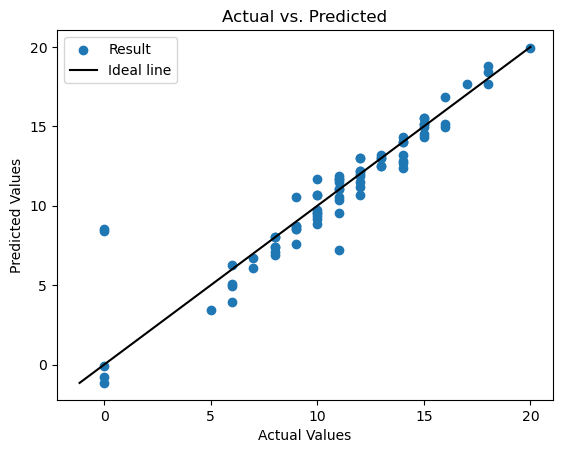

In [29]:
plt.scatter(y_test, predictions, label='Result')
min_val = min(min(y_test), min(predictions))
max_val = max(max(y_test), max(predictions))
plt.plot([min_val, max_val], [min_val, max_val], color = 'black', label='Ideal line')
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Actual vs. Predicted')
plt.legend()
plt.show()

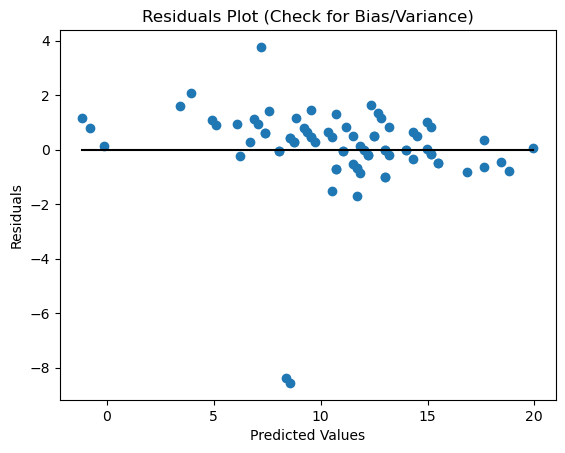

In [34]:
residuals = y_test - predictions
plt.scatter(predictions, residuals)
plt.plot([min(predictions), max(predictions)], [0, 0], color='black')
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')
plt.title('Residuals Plot (Check for Bias/Variance)')
plt.show()